# Introduction to Data Visualization with Matplotlib, Seaborn and Plotly

Welcome to the **Data Visualization** module! 

Data visualization is one of the most powerful tools in a data scientist's toolkit. A well-crafted chart can communicate a finding in seconds that would take paragraphs of text to explain. But with dozens of Python libraries available, choosing the right tool can feel overwhelming.

In this notebook we focus on the three most widely used libraries:

- **Matplotlib**: the foundation; complete control over every pixel

- **Seaborn**: statistical elegance built on top of Matplotlib

- **Plotly**: interactive, web-ready charts with minimal effort

By the end you will know not just *how* to use each library, but *when* and *why* to reach for each one.

## 1. Learning Objectives

By the end of this notebook, you will be able to:

1. Explain the **strengths and trade-offs** of Matplotlib, Seaborn, and Plotly

2. Create the most common **plot types** (scatter, bar, histogram, box, heatmap) in all three libraries

3. **Customise** colours, labels, titles, and styles to produce publication-ready figures

4. Use **subplots** to compare multiple views side by side

5. Build **interactive visualisations** with Plotly Express

6. Choose the **right library** for a given task or audience

## 2. The Python Visualization Ecosystem

### A quick history

Python's visualization landscape has grown organically over 20+ years.

- **2003**: Matplotlib released (modelled on MATLAB)

- **2012**: Seaborn released (statistical defaults, less boilerplate)

- **2015**: Plotly Python library released (interactive, browser-based)

Each library solved a problem the previous ones had. Understanding *why* each was created helps you understand *when* to use it.

### Library Comparison at a Glance

| Feature | Matplotlib | Seaborn | Plotly |
|---|---|---|---|
| **Level** | Low-level | High-level | High-level |
| **Interactivity** | Static | Static | Interactive |
| **Ease of use** | Verbose | Concise | Very concise |
| **Customisation** | Unlimited | Good via mpl | Good via layout |
| **Statistical plots** | Manual | Built-in | Via express |
| **Best for** | Fine control, publication | EDA, statistical summaries | Dashboards, presentations |
| **Output format** | PNG/SVG/PDF | PNG/SVG/PDF | HTML/JSON/PNG |

### When to use which library

**Use Matplotlib when:**

- You need pixel-perfect control (e.g. academic publication figures)
- You need a plot type that no higher-level library supports
- You are building a custom visualization from scratch

**Use Seaborn when:**

- You are doing exploratory data analysis (EDA)
- You want statistical summaries (confidence intervals, regression lines) automatically added
- You want beautiful defaults without writing much styling code

**Use Plotly when:**

- Your audience will interact with the chart (hover, zoom, filter)
- You are building a dashboard or web report
- You need animated charts or geographic maps

## 3. Setup & Data

### Meet the Palmer Penguins

Throughout this notebook we use the **Palmer Penguins** dataset, measurements of 344 penguins from three species collected on three islands in Antarctica.

It is a beginner-friendly alternative to the famous Iris dataset, with a richer mix of categorical and numerical columns.

| Column | Type | Description |
|---|---|---|
| `species` | categorical | Adelie, Chinstrap, or Gentoo |
| `island` | categorical | Biscoe, Dream, or Torgersen |
| `bill_length_mm` | numerical | Bill length in millimetres |
| `bill_depth_mm` | numerical | Bill depth in millimetres |
| `flipper_length_mm` | numerical | Flipper length in millimetres |
| `body_mass_g` | numerical | Body mass in grams |
| `sex` | categorical | male or female |


In [1]:
# --- Imports ---
# All three visualization libraries plus pandas for data handling
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

print("Libraries loaded successfully!")
print(f"  pandas  : {pd.__version__}")
print(f"  seaborn : {sns.__version__}")
import matplotlib

print(f"  matplotlib: {matplotlib.__version__}")
import plotly

print(f"  plotly  : {plotly.__version__}")

Libraries loaded successfully!
  pandas  : 3.0.3
  seaborn : 0.13.2
  matplotlib: 3.10.9
  plotly  : 6.7.0


In [2]:
# --- Show Plotly charts as static PNG pictures ---
# Plotly normally embeds the whole chart data in the notebook (megabytes).
# A PNG keeps the saved notebook small. Uses the kaleido package.
# Delete these two lines to get the interactive charts back.
import plotly.io as pio

pio.renderers.default = "png"

In [3]:
# --- Load the Palmer Penguins dataset ---
# The CSV is stored locally in the data/ folder
df = pd.read_csv("data/penguins_clean.csv")

# Quick sanity check
print(f"Shape: {df.shape}  ({df.shape[0]} rows, {df.shape[1]} columns)")
df.head()

Shape: (333, 7)  (333 rows, 7 columns)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male


In [4]:
# --- Inspect column names and data types ---
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    str    
 1   island             333 non-null    str    
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.3 KB


In [5]:
# --- Basic descriptive statistics ---
df.describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.00,333.00,333.00,333.00
mean,43.99,17.16,200.97,4207.06
std,5.47,1.97,14.02,805.22
min,32.10,13.10,172.00,2700.00
25%,39.50,15.60,190.00,3550.00
50%,44.50,17.30,197.00,4050.00
75%,48.60,18.70,213.00,4775.00
max,59.60,21.50,231.00,6300.00


In [6]:
# --- Check for missing values ---
# Missing values can silently affect plots, so always check first
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "ZERO, clean dataset!")

Missing values per column:
ZERO, clean dataset!


---

## 4. Matplotlib: Complete Control

**Matplotlib** is the bedrock of Python visualization. Almost every other library builds on top of it.

### Key concepts

- **`Figure`**: the entire canvas (like a blank sheet of paper)
- **`Axes`**: a single plot area within the figure (you can have many per figure)
- **Object-oriented API**: `fig, ax = plt.subplots()` gives you objects you can call methods on

### Pros of Matplotlib
- Supports virtually **every chart type** imaginable
- **Unlimited customisation**: every element can be changed
- Excellent for **publication-quality** static figures
- Huge community, extensive documentation

### Cons of Matplotlib
- **Verbose**: even simple charts require several lines
- **Default aesthetics** are not beautiful without styling
- Statistical features (confidence intervals, regression lines) must be computed manually
- No built-in interactivity


### 4.1 Line Plots: Trends Over Time (or sequence)

A **line plot** connects data points in order. Use them when your x-axis represents a sequence (time, rank, index) and you want to show how a value changes.

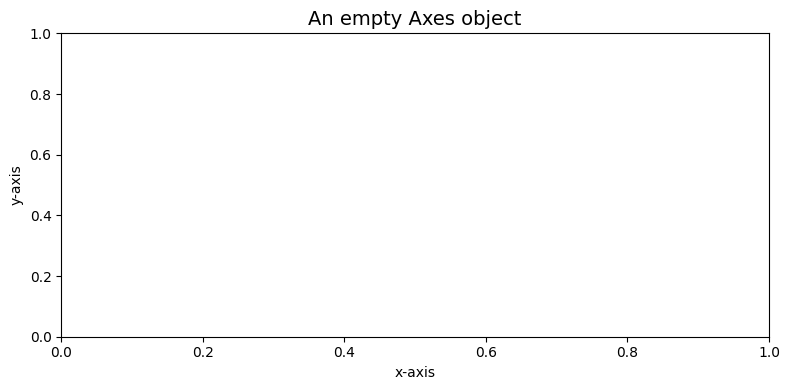

In [7]:
# --- Create a simple empty figure to understand the structure ---
fig, ax = plt.subplots(figsize=(8, 4))

# ax is now our 'drawing board'
ax.set_title("An empty Axes object", fontsize=14)
ax.set_xlabel("x-axis")
ax.set_ylabel("y-axis")

plt.tight_layout()
plt.show()

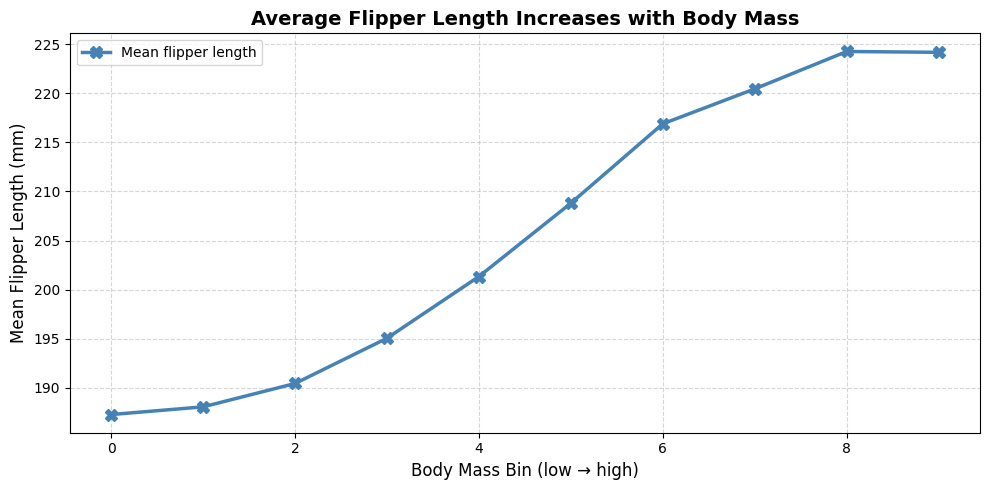

In [8]:
# --- Line plot: average flipper length per body mass bin ---
# Create 10 body-mass bins and calculate the mean flipper length in each
df_binned = df.copy()
df_binned["mass_bin"] = pd.cut(df["body_mass_g"], bins=10)
avg_flipper = df_binned.groupby("mass_bin", observed=True)["flipper_length_mm"].mean()

# --- Build the figure ---
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    range(len(avg_flipper)),  # x: bin index
    avg_flipper.values,  # y: mean flipper length
    color="steelblue",  # line color
    linewidth=2.5,  # line width
    marker="X",  # add a X at each data point
    markersize=8,  # marker size
    label="Mean flipper length",  # legend label
)

# --- Labels and styling ---
ax.set_title(
    "Average Flipper Length Increases with Body Mass", fontsize=14, fontweight="bold"
)
ax.set_xlabel("Body Mass Bin (low → high)", fontsize=12)
ax.set_ylabel("Mean Flipper Length (mm)", fontsize=12)
ax.legend()
ax.grid(
    True, linestyle="--", alpha=0.5
)  # add a light grid for better readability and alpha for subtlety

plt.tight_layout()  # adjusts layout to prevent clipping of labels
plt.show()  # displays the plot

### 4.2 Scatter Plots: Relationships Between Two Variables

A **scatter plot** shows each observation as a dot. Use them to reveal correlations, clusters, and outliers between two numerical variables.

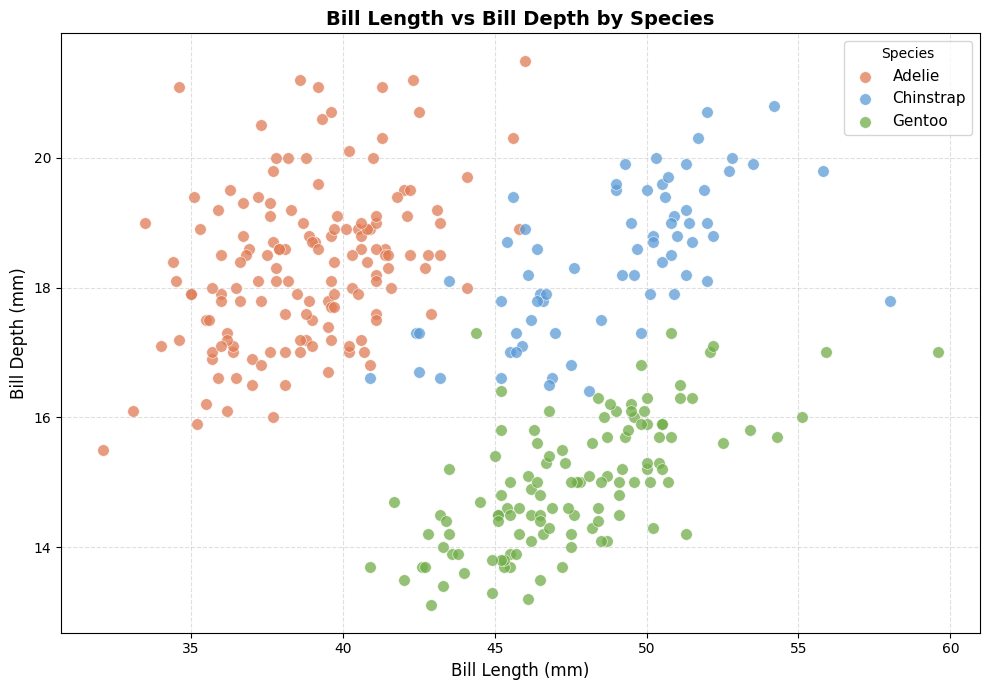

In [9]:
# --- Scatter plot: bill length vs bill depth, coloured by species ---
# First, create a colour map (dictionary) for the three species
species_colours = {
    "Adelie": "#E07B54",  # warm orange
    "Chinstrap": "#5B9BD5",  # blue
    "Gentoo": "#70AD47",  # green
}

fig, ax = plt.subplots(figsize=(10, 7))

# --- Plot each species separately to get labelled legend entries ---
for species, colour in species_colours.items():
    subset = df[df["species"] == species]
    ax.scatter(
        subset["bill_length_mm"],
        subset["bill_depth_mm"],
        c=colour,
        label=species,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.5,
        s=70,  # marker size
    )

# --- Labels and formatting ---
ax.set_title("Bill Length vs Bill Depth by Species", fontsize=14, fontweight="bold")
ax.set_xlabel("Bill Length (mm)", fontsize=12)
ax.set_ylabel("Bill Depth (mm)", fontsize=12)
ax.legend(title="Species", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Notice: overall the data looks like bill depth DECREASES with length (negative correlation),
# but WITHIN each species it actually INCREASES!
# This is called "Simpson's Paradox".

### 4.3 Bar Charts: Comparing Categories

**Bar charts** are the go-to for comparing a numerical value across categories. A key design decision: **vertical** bars are best for categories with short labels; **horizontal** bars are better for long labels or many categories.

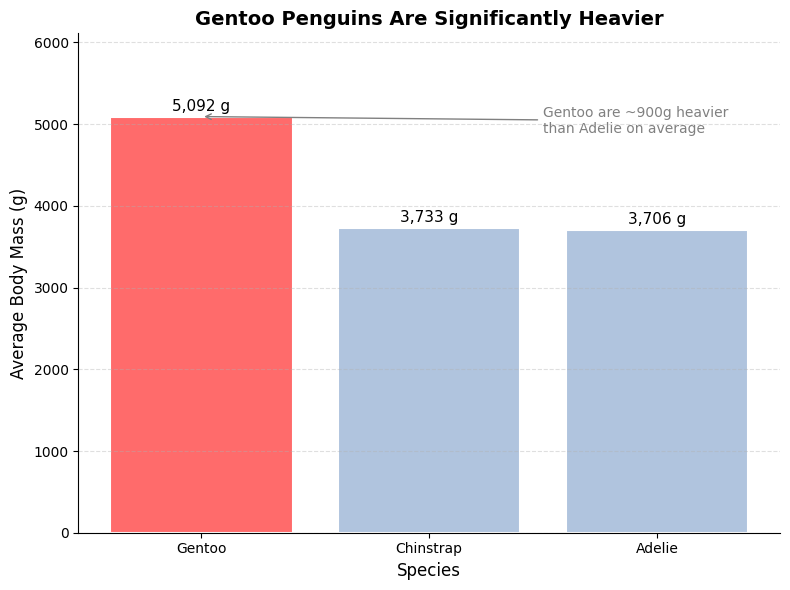

In [10]:
# --- Bar chart: average body mass per species ---
# Calculate group means
avg_mass = df.groupby("species")["body_mass_g"].mean().sort_values(ascending=False)

# --- Colour scheme: highlight Gentoo as the heaviest ---
highlight_colour = "#FF6B6B"  # red for the highlighted bar
default_colour = "#B0C4DE"  # light steel blue for others

bar_colours = [
    highlight_colour if sp == "Gentoo" else default_colour for sp in avg_mass.index
]

fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(
    avg_mass.index, avg_mass.values, color=bar_colours, edgecolor="white", linewidth=1.5
)

# --- Add value labels on top of each bar ---
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 30,
        f"{height:,.0f} g",
        ha="center",
        va="bottom",
        fontsize=11,
    )

# --- Annotation pointing out the key insight ---
ax.annotate(
    "Gentoo are ~900g heavier\nthan Adelie on average",
    xy=(0, avg_mass["Gentoo"]),
    xytext=(1.5, avg_mass["Gentoo"] - 200),
    arrowprops=dict(arrowstyle="->", color="grey"),
    fontsize=10,
    color="grey",
)

ax.set_title(
    "Gentoo Penguins Are Significantly Heavier", fontsize=14, fontweight="bold"
)
ax.set_ylabel("Average Body Mass (g)", fontsize=12)
ax.set_xlabel("Species", fontsize=12)
ax.set_ylim(0, avg_mass.max() * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### 4.4 Histograms: Understanding Distributions

A **histogram** bins continuous values and shows the frequency of each bin. It is the primary tool for understanding the *shape* of a distribution (normal, skewed, bimodal, etc.).

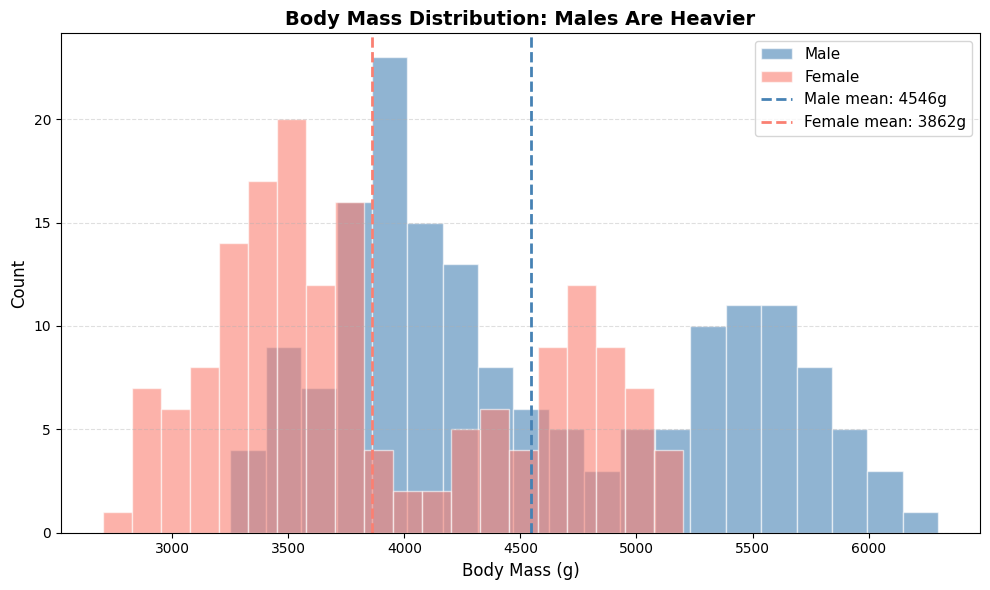

In [11]:
# --- Histogram: body mass distribution, split by sex ---
# Separate into male and female
df_male = df[df["sex"] == "male"]
df_female = df[df["sex"] == "female"]

fig, ax = plt.subplots(figsize=(10, 6))

# --- Overlapping histograms with transparency ---
ax.hist(
    df_male["body_mass_g"],
    bins=20,
    alpha=0.6,
    color="steelblue",
    label="Male",
    edgecolor="white",
)
ax.hist(
    df_female["body_mass_g"],
    bins=20,
    alpha=0.6,
    color="salmon",
    label="Female",
    edgecolor="white",
)

# --- Add vertical lines for the means ---
ax.axvline(
    df_male["body_mass_g"].mean(),
    color="steelblue",
    linestyle="--",
    linewidth=2,
    label=f"Male mean: {df_male['body_mass_g'].mean():.0f}g",
)
ax.axvline(
    df_female["body_mass_g"].mean(),
    color="salmon",
    linestyle="--",
    linewidth=2,
    label=f"Female mean: {df_female['body_mass_g'].mean():.0f}g",
)

ax.set_title(
    "Body Mass Distribution: Males Are Heavier", fontsize=14, fontweight="bold"
)
ax.set_xlabel("Body Mass (g)", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 4.5 Subplots: Side-by-Side Comparisons

**Subplots** let you place multiple plots on a single figure. This is essential for communicating comparisons without forcing the reader to switch between charts.

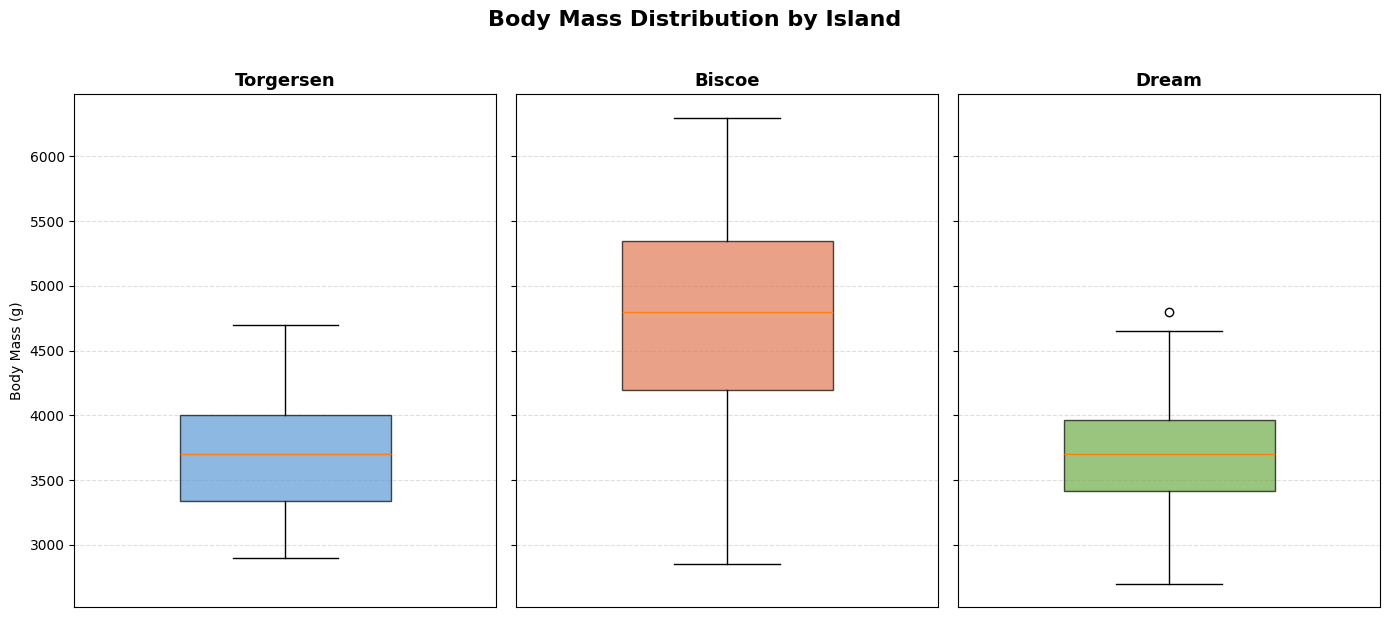

In [12]:
# --- Subplots: one box plot per island ---
islands = df["island"].unique()
n_islands = len(islands)

fig, axes = plt.subplots(nrows=1, ncols=n_islands, figsize=(14, 6), sharey=True)

# --- Loop through each island and create a box plot ---
colours = ["#5B9BD5", "#E07B54", "#70AD47"]

for ax, island, colour in zip(axes, islands, colours):
    island_data = df[df["island"] == island]["body_mass_g"].dropna()

    bp = ax.boxplot(
        island_data,
        patch_artist=True,  # fill box with colour
        notch=False,
        widths=0.5,
    )

    # Colour the box
    bp["boxes"][0].set_facecolor(colour)
    bp["boxes"][0].set_alpha(0.7)

    ax.set_title(island, fontsize=13, fontweight="bold")
    ax.set_ylabel("Body Mass (g)" if ax == axes[0] else "")
    ax.set_xticks([])
    ax.grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle("Body Mass Distribution by Island", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 4.6 Styling with Style Sheets

Matplotlib ships with pre-built style sheets that change the overall look instantly. Think of them as themes. Run `plt.style.available` to see all options.

In [13]:
# --- See all available styles ---
print("Available styles:", plt.style.available)

Available styles: ['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


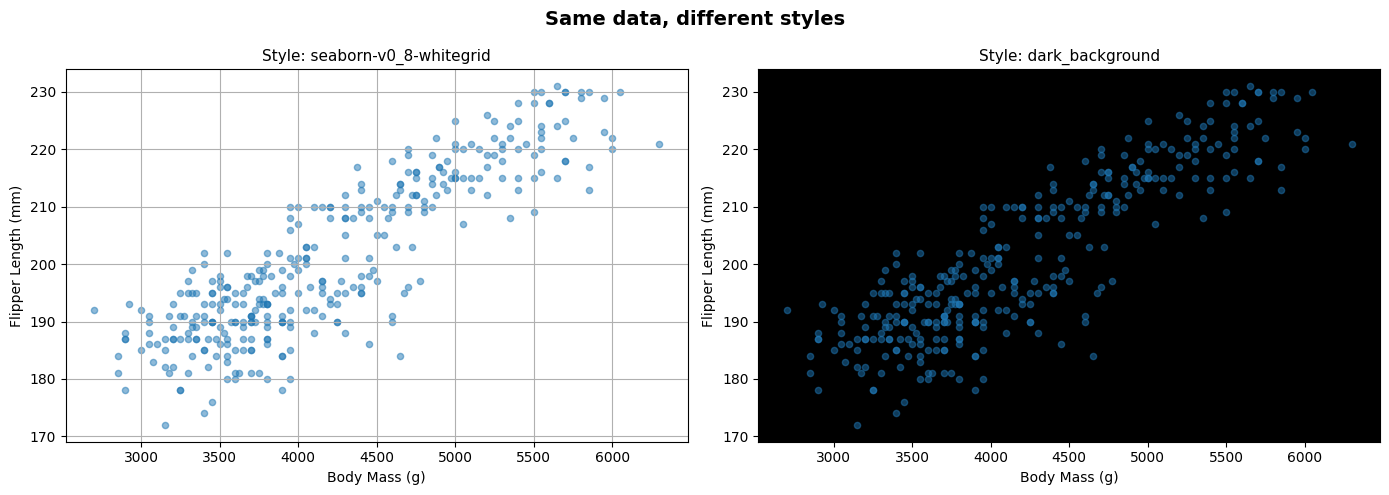

In [14]:
# --- Compare two styles side by side ---
styles = ["seaborn-v0_8-whitegrid", "dark_background"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, style in zip(axes, styles):

    with plt.style.context(style):

        ax.set_facecolor(plt.rcParams["axes.facecolor"])

        ax.scatter(
            df["body_mass_g"],
            df["flipper_length_mm"],
            alpha=0.5,
            s=20
        )

        ax.grid(plt.rcParams["axes.grid"])

        ax.set_title(f"Style: {style}",fontsize=11)
        ax.set_xlabel("Body Mass (g)")
        ax.set_ylabel("Flipper Length (mm)")

plt.suptitle("Same data, different styles",fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

---

## Checkpoint 1: Matplotlib

Before moving on, check your understanding:

1. **What is the difference between a `Figure` and an `Axes` in Matplotlib?**
   *(Hint: think canvas vs. drawing area)*

<details>
<summary>Show answer</summary>

A Figure is the whole canvas that holds everything. An Axes is a single plotting area inside that Figure, with its own x-axis, y-axis, title, and data. One Figure can contain many Axes, which is exactly how subplots work. When you write `fig, ax = plt.subplots()`, `fig` is the canvas and `ax` is the one drawing area you plot into.
</details>

2. **What argument controls transparency in `ax.scatter()` or `ax.hist()`?** 
   *(Hint: it's a value between 0 and 1)*

<details>
<summary>Show answer</summary>

The `alpha` argument. It takes a value from 0 (fully transparent) to 1 (fully opaque). Lower values are useful when points or bars overlap, because you can still see the density of the data through the see-through layers.
</details>

3. **How would you create a 2×2 grid of subplots?** Write the one line of code.

<details>
<summary>Show answer</summary>

`fig, axes = plt.subplots(nrows=2, ncols=2)` (or the shorthand `plt.subplots(2, 2)`). This returns the Figure plus a 2x2 array of Axes, which you index as `axes[0, 0]` or flatten with `axes.flatten()` to loop over.
</details>

4. **Name one situation where a horizontal bar chart is better than a vertical one.**

<details>
<summary>Show answer</summary>

When the category labels are long. On a horizontal bar chart the labels sit along the y-axis and stay readable, instead of being squeezed or rotated under a vertical axis. It also helps when there are many categories, since vertical space extends more naturally than a fixed-width horizontal axis.
</details>

5. **`ax.axvline(x=5)` draws a vertical line at x=5. What would `ax.axhline(y=5)` draw?**

<details>
<summary>Show answer</summary>

It draws a horizontal line across the plot at y=5. `axvline` draws a vertical line at a given x value, and `axhline` is its mirror: a horizontal line at a given y value. Both are handy for marking a threshold or reference value.
</details>

> **Try it yourself**: In a new cell, create a figure with two subplots side by side. In the left one, plot a histogram of `bill_length_mm`. In the right one, plot a histogram of `bill_depth_mm`. Give each a title.

**My solution (Try it yourself, Matplotlib)**

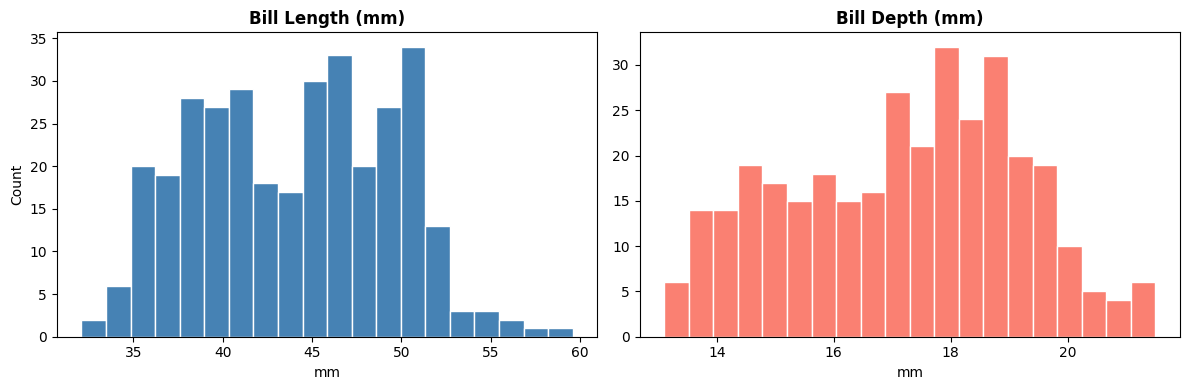

In [15]:
# --- Two histograms side by side ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: bill length
axes[0].hist(df["bill_length_mm"], bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Bill Length (mm)", fontweight="bold")
axes[0].set_xlabel("mm")
axes[0].set_ylabel("Count")

# Right: bill depth
axes[1].hist(df["bill_depth_mm"], bins=20, color="salmon", edgecolor="white")
axes[1].set_title("Bill Depth (mm)", fontweight="bold")
axes[1].set_xlabel("mm")

plt.tight_layout()
plt.show()

# Both histograms have two humps (bimodal): a hint that species are mixed together.

---

## 5. Seaborn: Statistical Elegance

**Seaborn** was built specifically for data science. It handles the statistical heavy-lifting (confidence intervals, regression lines, KDE curves) automatically, and its defaults look polished right out of the box.

### Pros of Seaborn
- Beautiful **default aesthetics**: looks professional without custom styling
- **Statistical summaries** built in (confidence intervals, regression, KDE)
- Excellent at **multi-dimensional** visualizations (split by hue, column, row)
- Works seamlessly with pandas DataFrames

### Cons of Seaborn
- Less flexible than raw Matplotlib for unusual customisations
- Can be slower on very large datasets
- No interactivity
- Two API styles (`axes-level` vs `figure-level`) can be confusing at first

### Two API Styles

Seaborn has two families of functions:

| Style | Functions | Returns | When to use |
|---|---|---|---|
| **Axes-level** | `sns.scatterplot()`, `sns.histplot()`, etc. | `Axes` object | When integrating into a larger Matplotlib figure |
| **Figure-level** | `sns.relplot()`, `sns.displot()`, `sns.catplot()` | `FacetGrid` object | When you want automatic multi-panel figures |


### 5.1 Scatter & Regression Plots

With Seaborn, adding a **regression line** to a scatter plot is a single extra argument, no manual calculation needed.

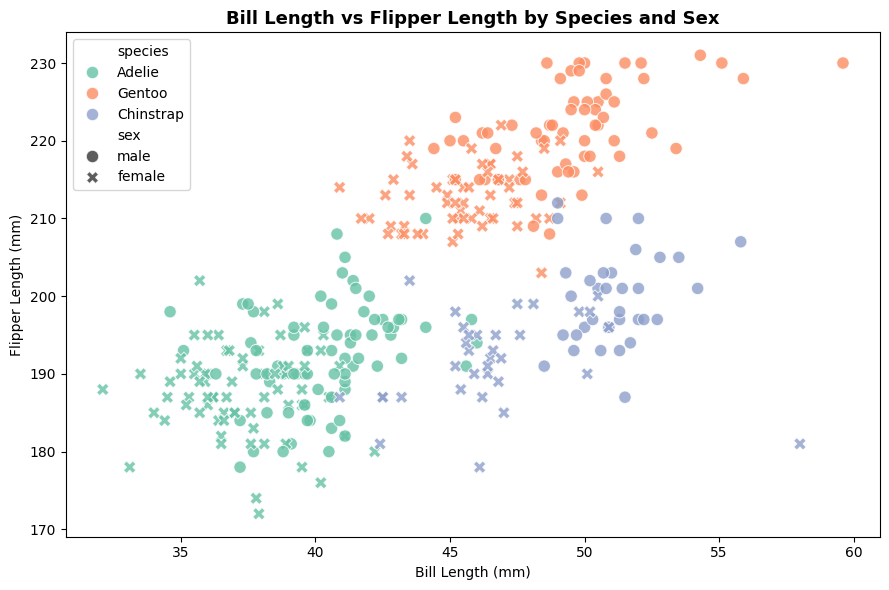

In [16]:
# --- Axes-level scatter: bill length vs flipper length, coloured by species ---
fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="species",  # colour by species
    style="sex",  # marker shape by sex
    palette="Set2",
    alpha=0.8,
    s=80,
    ax=ax,
)

ax.set_title(
    "Bill Length vs Flipper Length by Species and Sex", fontsize=13, fontweight="bold"
)
ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Flipper Length (mm)")
plt.tight_layout()
plt.show()

# Notice: Seaborn automatically created a colour legend AND a style legend

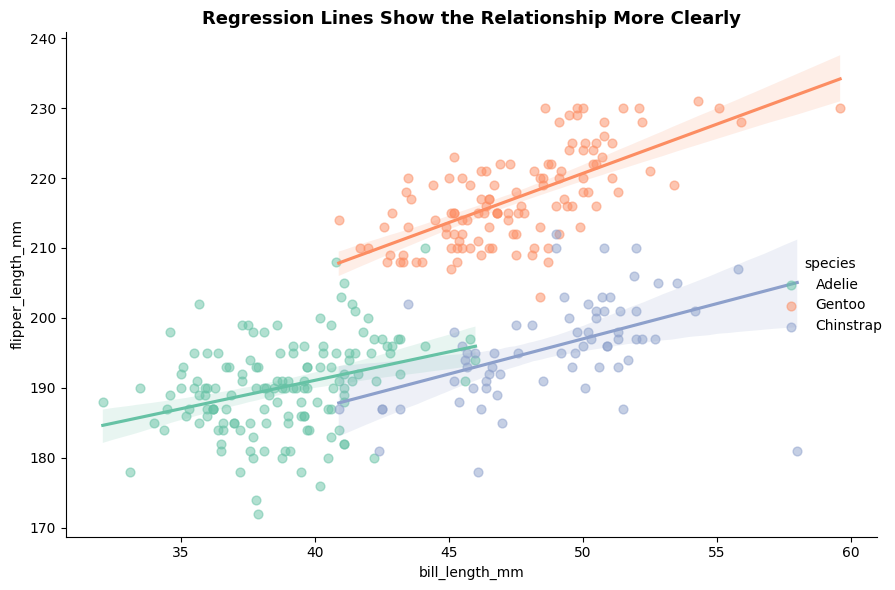

In [17]:
# --- lmplot: scatter WITH a regression line per species ---
# lmplot is a figure-level function, no ax= argument
sns.lmplot(
    data=df,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="species",
    palette="Set2",
    height=6,
    aspect=1.3,
    scatter_kws={"alpha": 0.5, "s": 40},
)

plt.title(
    "Regression Lines Show the Relationship More Clearly",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# The shaded band around each line is the 95% confidence interval, free with Seaborn!

### 5.2 Distribution Plots

Seaborn's **`displot`** and **`histplot`** make it easy to visualise distributions with KDE overlays and rug plots. These are much richer than a plain `ax.hist()`.

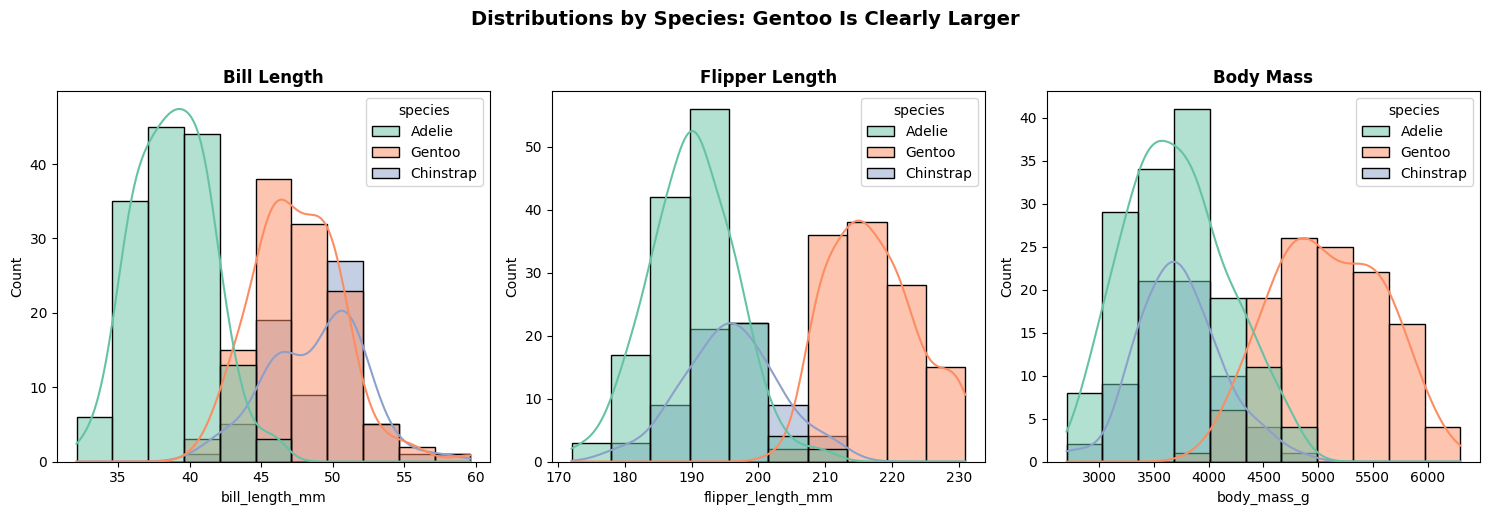

In [18]:
# --- histplot with KDE overlay ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

numeric_cols = ["bill_length_mm", "flipper_length_mm", "body_mass_g"]
titles = ["Bill Length", "Flipper Length", "Body Mass"]

for ax, col, title in zip(axes, numeric_cols, titles):
    sns.histplot(
        data=df,
        x=col,
        hue="species",
        kde=True,  # overlay a KDE (kernel density estimate) curve
        palette="Set2",
        alpha=0.5,
        ax=ax,
    )
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(col)

plt.suptitle(
    "Distributions by Species: Gentoo Is Clearly Larger",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

### 5.3 Categorical Plots: Violin, Box, and Strip

Seaborn's `catplot` gives access to a family of plots designed for categorical x-axes. Key types:

- **`box`**: shows median, IQR, and outliers
- **`violin`**: shows the full distribution shape (KDE)
- **`strip`**: shows individual data points
- **`swarm`**: like strip but avoids overlapping points

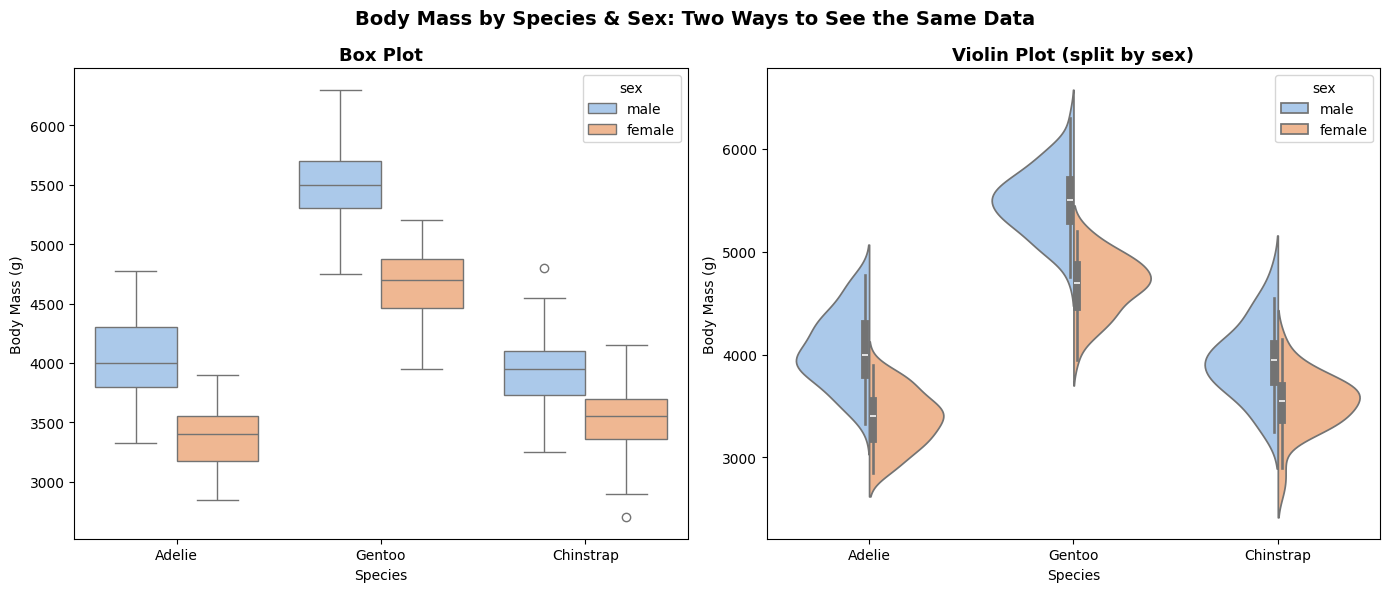

In [19]:
# --- Side-by-side: boxplot vs violinplot for body mass by species ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Box plot ---
sns.boxplot(
    data=df, x="species", y="body_mass_g", hue="sex", palette="pastel", ax=axes[0]
)
axes[0].set_title("Box Plot", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Body Mass (g)")

# --- Violin plot (same data) ---
sns.violinplot(
    data=df,
    x="species",
    y="body_mass_g",
    hue="sex",
    split=True,  # split violin by hue
    palette="pastel",
    ax=axes[1],
)
axes[1].set_title("Violin Plot (split by sex)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Species")
axes[1].set_ylabel("Body Mass (g)")

plt.suptitle(
    "Body Mass by Species & Sex: Two Ways to See the Same Data",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# Box plot tells you: median, spread, outliers
# Violin plot tells you: the full shape of the distribution (bimodal? skewed?)

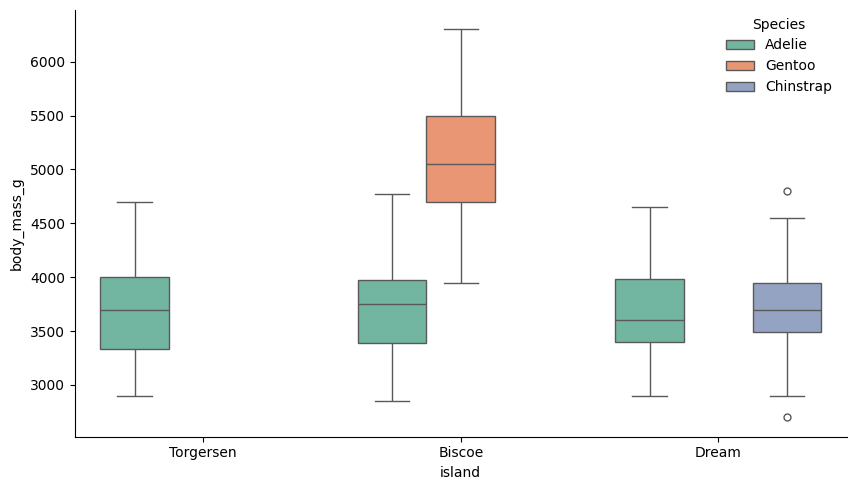

In [20]:
# --- catplot with multiple kinds for comparison ---
# catplot is figure-level, creates its own figure automatically
g = sns.catplot(
    data=df,
    x="island",
    y="body_mass_g",
    hue="species",
    kind="box",
    palette="Set2",
    height=5,
    aspect=1.5,
)

# Remove seaborn's default legend and rebuild on the axes
sns.move_legend(g, "upper right", bbox_to_anchor=(0.98, 0.98), title="Species")

plt.tight_layout()
plt.show()

### 5.4 Heatmaps: Correlation Matrices

A **heatmap** encodes a matrix of values as colours. The most common use in EDA is a **correlation matrix**: which pairs of numerical variables move together?

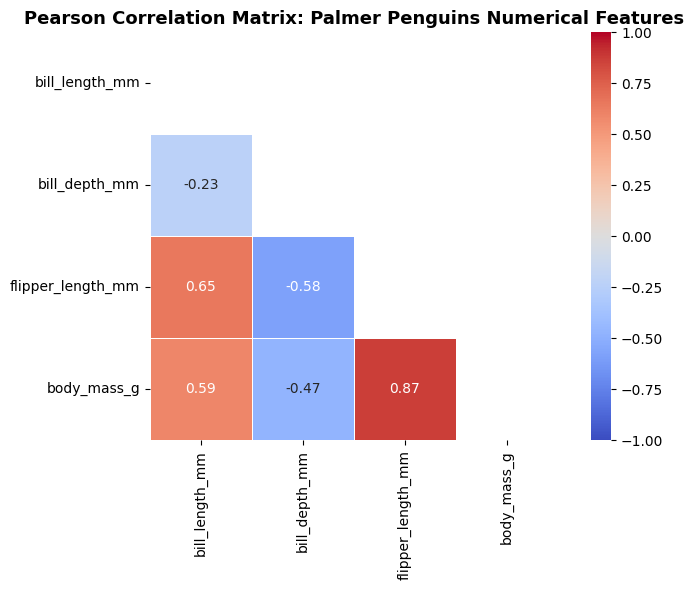

In [21]:
# --- Correlation heatmap ---
# Step 1: Calculate the correlation matrix
numeric_df = df.select_dtypes(include="number")
corr_matrix = numeric_df.corr(method="pearson").round(2)

# Step 2: Create a mask to hide the upper triangle (it's a mirror of the lower)
import numpy as np

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Step 3: Plot
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,  # show the number in each cell
    fmt=".2f",
    cmap="coolwarm",  # red = positive, blue = negative correlation
    vmin=-1,
    vmax=1,  # fix the colour scale
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title(
    "Pearson Correlation Matrix: Palmer Penguins Numerical Features",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# Values close to +1: strong positive correlation (both go up together)
# Values close to -1: strong negative correlation (one goes up, other goes down)
# Values close to  0: little or no linear relationship

### 5.5 Pair Plots: All Relationships at Once

A **pair plot** creates a grid of scatter plots for every pair of numerical variables. The diagonal shows distributions. It is the fastest single command for EDA on a multi-variable dataset.

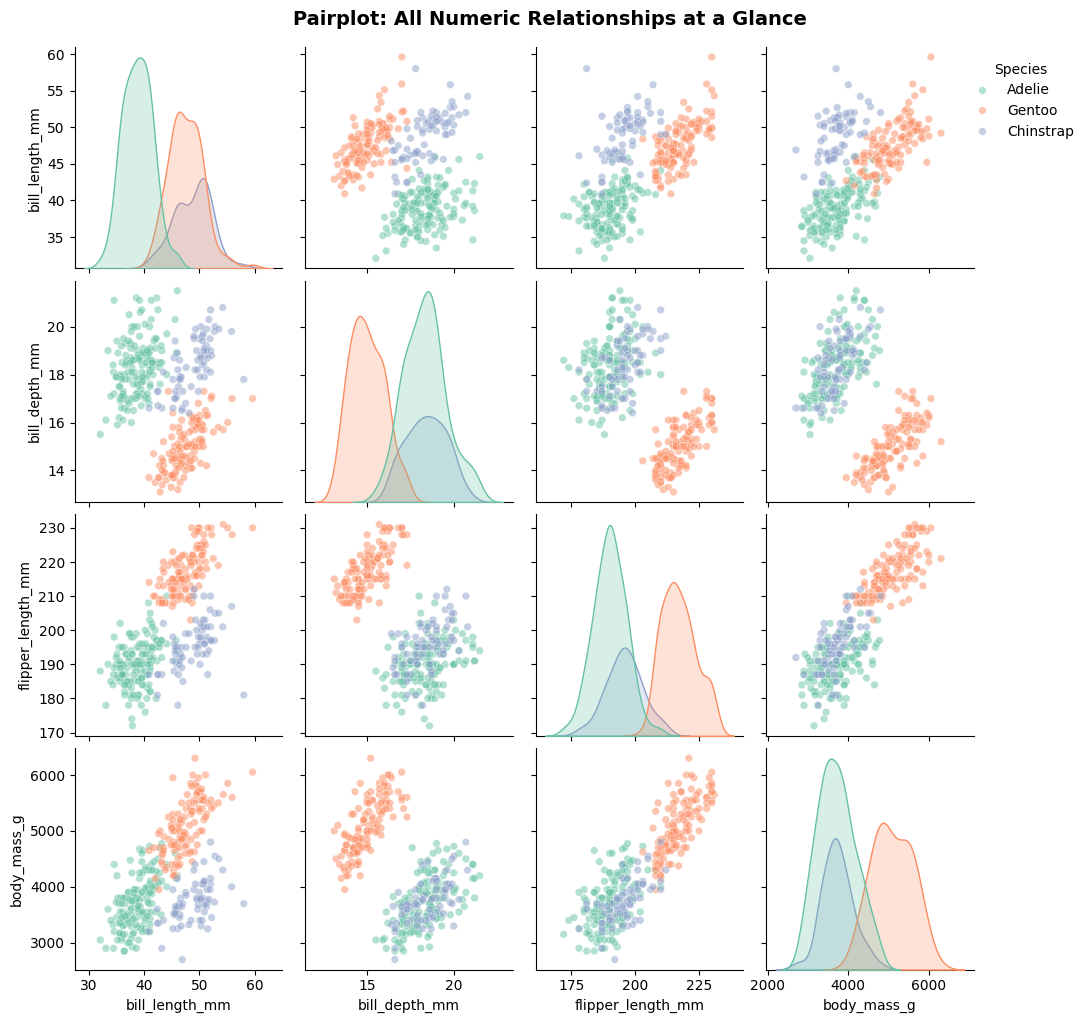

In [22]:
# --- Pairplot: all numeric features coloured by species ---
# This creates a 4x4 grid automatically
g = sns.pairplot(
    data=df,
    hue="species",
    palette="Set2",
    diag_kind="kde",  # show KDE on the diagonal (or 'hist')
    plot_kws={"alpha": 0.5, "s": 30},
)

# Remove seaborn's default legend and rebuild on the axes
sns.move_legend(g, "upper right", bbox_to_anchor=(0.98, 0.98), title="Species")

g.figure.suptitle(
    "Pairplot: All Numeric Relationships at a Glance",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.show()

### 5.6 Figure-Level Functions: `relplot` and Multi-Panel Plots

Figure-level functions like `relplot` and `catplot` automatically create **multi-panel grids**. Use the `col=` and `row=` arguments to split by a categorical variable.

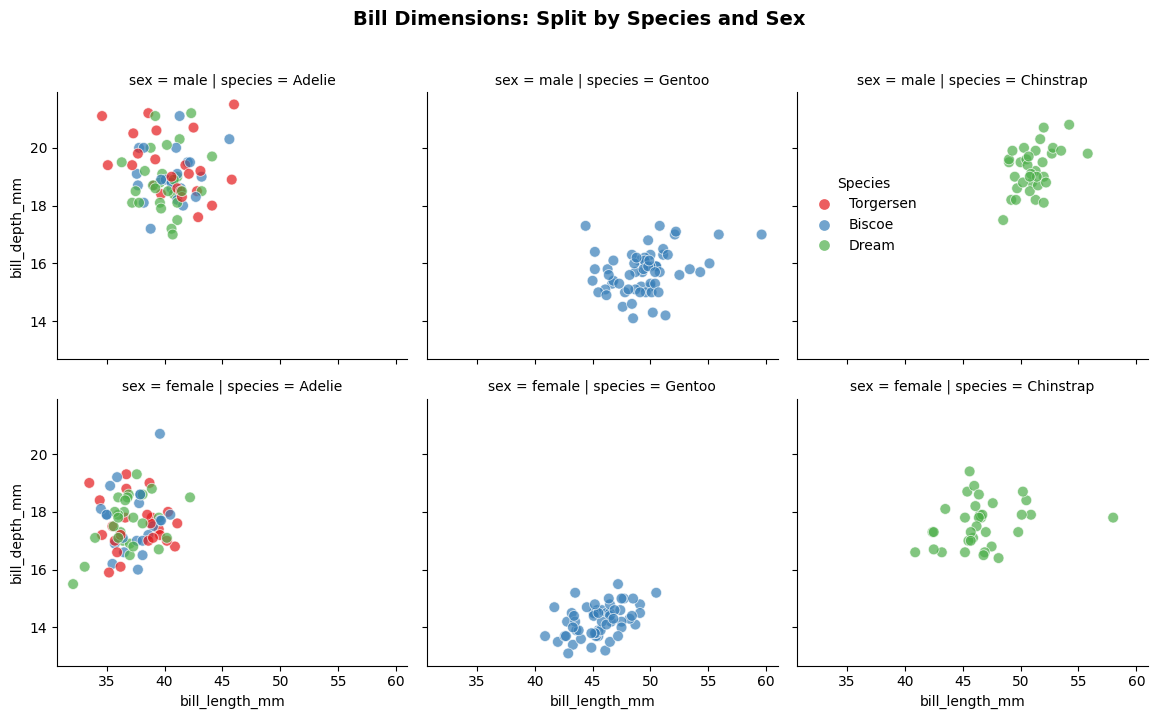

In [23]:
# --- relplot: scatter split by species (col) and sex (row) ---
g = sns.relplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="island",
    col="species",  # one column per species
    row="sex",  # one row per sex
    palette="Set1",
    s=60,
    alpha=0.7,
    height=3.5,
    aspect=1,
)

# Remove seaborn's default legend and rebuild on the axes
sns.move_legend(g, "upper right", bbox_to_anchor=(0.80, 0.80), title="Species")

plt.suptitle(
    "Bill Dimensions: Split by Species and Sex", fontsize=14, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

---

## Checkpoint 2: Seaborn

1. **What is the key difference between a *box plot* and a *violin plot*?**
   What does a violin plot show that a box plot does not?

<details>
<summary>Show answer</summary>

A box plot summarises a distribution with five numbers: the median, the lower and upper quartiles (the box), the whiskers, and any outliers. A violin plot keeps that idea but adds the full shape of the distribution as a mirrored density curve. So the violin shows what a box hides, such as whether the data is bimodal (two peaks) or skewed, not just its spread.
</details>

2. **In Seaborn, what does the shaded band around a regression line represent?**

<details>
<summary>Show answer</summary>

It is the 95% confidence interval for the regression line. It shows the range where the true line is likely to fall given the data, so a wide band means more uncertainty (few or noisy points) and a narrow band means a more precise fit. Seaborn computes and draws it for you automatically.
</details>

3. **What does a correlation value of `−0.87` between two columns mean?**

<details>
<summary>Show answer</summary>

It is a strong negative linear relationship: as one variable goes up, the other tends to go down. Correlation runs from -1 to +1, so a value near -0.87 is close to -1 and therefore strong, and the minus sign tells you the direction is inverse. It measures the strength and direction of a straight-line relationship, not causation.
</details>

4. **When would you use `sns.catplot()` instead of `sns.boxplot()`?**
   *(Hint: think about what extra argument catplot supports)*

<details>
<summary>Show answer</summary>

Use `sns.catplot()` when you want Seaborn to build a multi-panel figure automatically, splitting the data into separate subplots with `col=` or `row=`. It is a figure-level function that manages the whole grid, while `sns.boxplot()` is axes-level and draws into a single Axes you control. Those `col=` and `row=` arguments are the extra ones the hint points at.
</details>

5. **In a heatmap, if `bill_length_mm` and `flipper_length_mm` have a correlation of `0.87`, what would you expect to see on the scatter plot between them?**

<details>
<summary>Show answer</summary>

You would expect the points to form a clear upward-sloping band: as bill length increases, flipper length tends to increase too. A correlation of 0.87 is strong and positive, so the cloud of points hugs an imaginary rising line fairly tightly, though not perfectly (1.0 would be a perfect straight line).
</details>

> **Try it yourself**: Run `sns.catplot(data=df, x='species', y='flipper_length_mm', kind='violin', hue='sex', split=True)`. Change `kind=` to `'box'`, `'strip'`, and `'swarm'`. Which one gives you the most information?

**My solution (Try it yourself, Seaborn)**

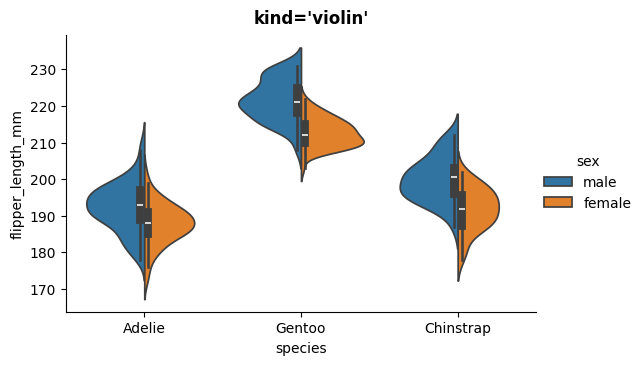

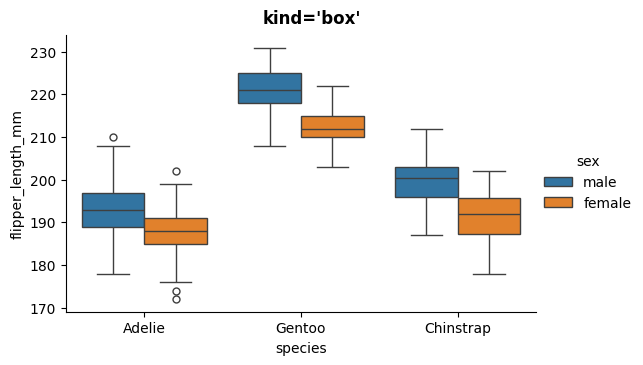

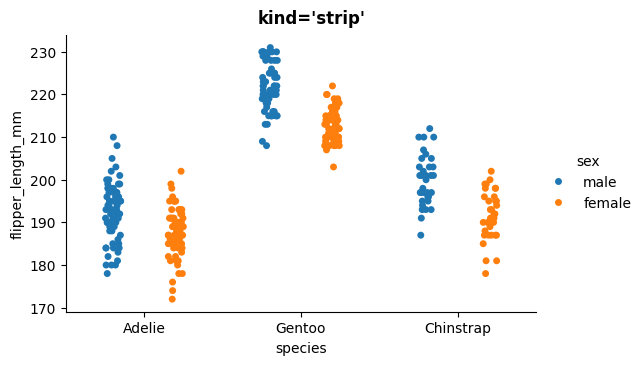

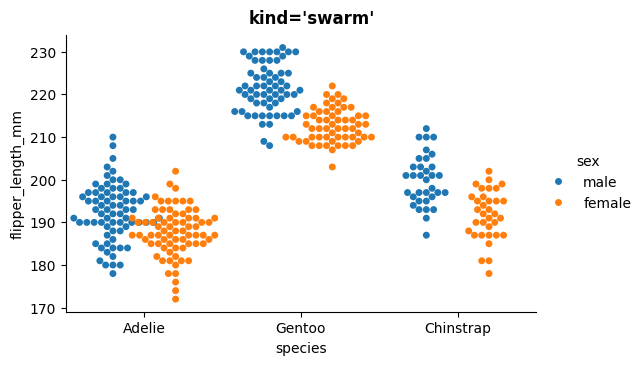

In [24]:
# --- The same data drawn with four different catplot kinds ---
# One figure per kind, so we can compare what each one shows.
for kind in ["violin", "box", "strip", "swarm"]:
    extra = {"split": True} if kind == "violin" else {}  # split only exists for violins
    extra.update({"dodge": True} if kind in ["strip", "swarm"] else {})
    g = sns.catplot(
        data=df,
        x="species",
        y="flipper_length_mm",
        hue="sex",
        kind=kind,
        height=3.5,
        aspect=1.6,
        **extra,
    )
    g.figure.suptitle(f"kind='{kind}'", y=1.03, fontweight="bold")
    plt.show()

**My answer:** the split **violin** gives the most information at a glance: it shows the full shape of each distribution and compares males and females in one shape. The **swarm** plot is the most honest one for a small dataset like this, because it shows every single penguin. The **box** plot is the most compact summary (median, quartiles, outliers), and the **strip** plot shows all points but they overlap.

---

## 6. Plotly: Interactive Visualizations

**Plotly** renders charts as interactive HTML elements. Every plot is live in your browser, hover for details, zoom, pan, click legend entries to toggle groups.

### Pros of Plotly
- **Interactive by default**: hover tooltips, zoom, pan, export PNG
- Beautiful modern aesthetics out of the box
- Excellent for **geographic maps**, **animations**, and **3D plots**
- Charts can be exported as standalone HTML files for sharing

### Cons of Plotly
- Heavier than Matplotlib / Seaborn (larger file sizes)
- Interactive output is not easily included in PDF reports
- Customisation uses a different syntax (`update_layout`, `update_traces`), a new API to learn

### Plotly Express vs Graph Objects

Plotly has two APIs:

- **`plotly.express` (`px`)**: high-level, concise, great for 90% of use cases
- **`plotly.graph_objects` (`go`)**: low-level, verbose but offers full control

We will focus on `px` as it is the recommended starting point.

### 6.1 Interactive Scatter Plots

A Plotly scatter immediately gains hover tooltips, zoom, and pan. Try interacting with the chart below!

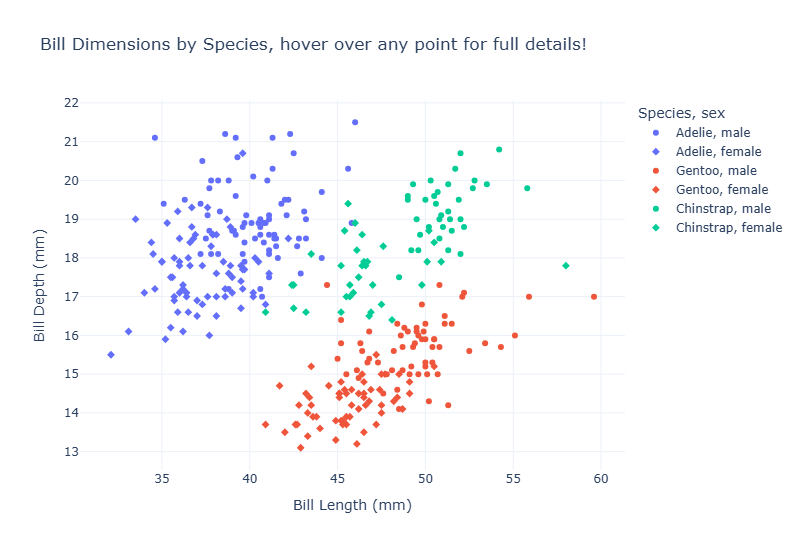

In [25]:
# --- Interactive scatter: bill length vs depth ---
# hover_data adds extra columns to the tooltip when you hover over a point
fig = px.scatter(
    data_frame=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    color="species",
    symbol="sex",
    hover_data=["island", "body_mass_g", "flipper_length_mm"],
    title="Bill Dimensions by Species, hover over any point for full details!",
    labels={
        "bill_length_mm": "Bill Length (mm)",
        "bill_depth_mm": "Bill Depth (mm)",
        "species": "Species",
    },
    template="plotly_white",
    width=800,
    height=550,
)

fig.show()

# Try: click a species in the legend to hide/show it
# Try: hover over a point to see all the columns in hover_data
# Try: drag to zoom in, double-click to reset

### 6.2 Interactive Bar Charts

Bar charts in Plotly can be grouped, stacked, and animated. The `color=` argument automatically creates a grouped bar if there are multiple values.

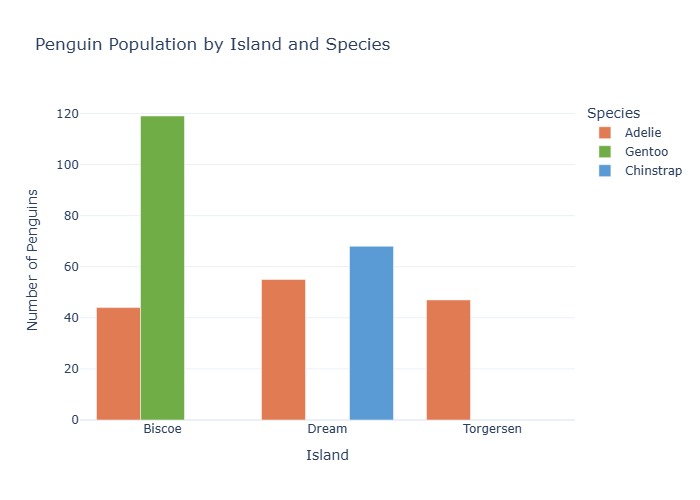

In [26]:
# --- Grouped bar chart: count of penguins by species and island ---
# First create a summary table
count_df = df.groupby(["island", "species"]).size().reset_index(name="count")

fig = px.bar(
    count_df,
    x="island",
    y="count",
    color="species",
    barmode="group",  # 'group' (side by side) or 'stack'
    title="Penguin Population by Island and Species",
    labels={"count": "Number of Penguins", "island": "Island"},
    template="plotly_white",
    color_discrete_map={
        "Adelie": "#E07B54",
        "Chinstrap": "#5B9BD5",
        "Gentoo": "#70AD47",
    },
    width=700,
    height=500,
)

fig.update_layout(legend_title_text="Species")
fig.show()

# Notice that Gentoo only lives on Biscoe, Chinstrap only on Dream!

### 6.3 Box and Violin Plots in Plotly

Interactive box/violin plots are especially powerful because you can hover to see exact statistics, and toggle groups via the legend.

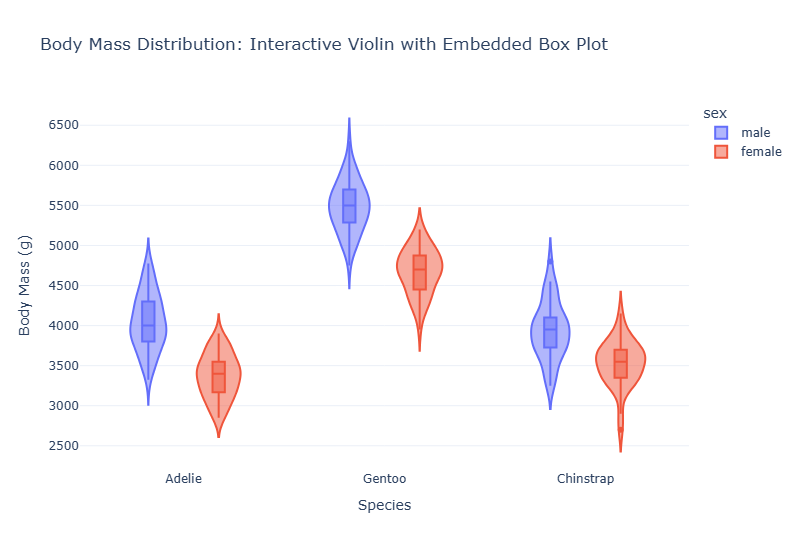

In [27]:
# --- Interactive violin plot: body mass by species, split by sex ---
fig = px.violin(
    df,
    x="species",
    y="body_mass_g",
    color="sex",
    box=True,  # embed a box plot inside the violin
    points="outliers",  # show outlier points only (or 'all' or False)
    hover_data=df.columns,
    title="Body Mass Distribution: Interactive Violin with Embedded Box Plot",
    labels={"body_mass_g": "Body Mass (g)", "species": "Species"},
    template="plotly_white",
    width=800,
    height=550,
)

fig.show()

### 6.4 Heatmaps in Plotly

An interactive heatmap lets you hover to see exact values, very handy for large correlation matrices.

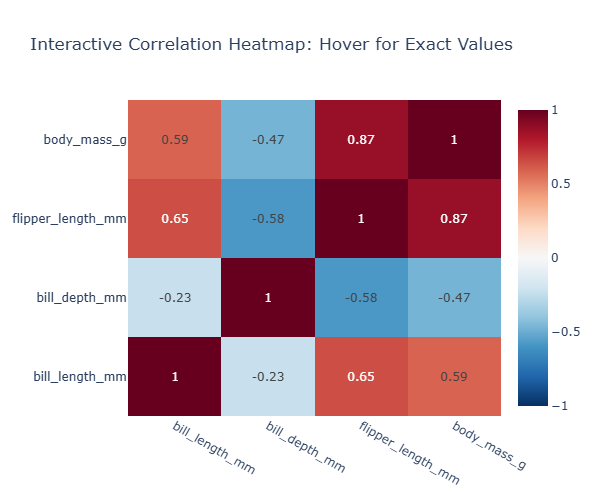

In [28]:
# --- Interactive correlation heatmap ---
import numpy as np

# Recalculate correlation matrix
corr = df.select_dtypes(include="number").corr(method="pearson").round(2)

fig = go.Figure(
    data=go.Heatmap(
        z=corr.values,
        x=corr.columns.tolist(),
        y=corr.index.tolist(),
        colorscale="RdBu_r",  # red = positive, blue = negative
        zmin=-1,
        zmax=1,
        text=corr.values,
        texttemplate="%{text}",
        showscale=True,
    )
)

fig.update_layout(
    title="Interactive Correlation Heatmap: Hover for Exact Values",
    width=600,
    height=500,
    template="plotly_white",
)

fig.show()

### 6.5 Geographic Maps: Choropleth

Plotly makes **geographic visualizations** surprisingly easy. A **choropleth** map colours regions by a numerical value, like a heatmap overlaid on a map.

The example below uses US county-level unemployment data fetched from a public URL.

In [29]:
# --- Choropleth: US county unemployment rates ---
# Step 1: Load GeoJSON boundaries for US counties
# GeoJSON is a standard format for encoding geographic shapes
import json
from urllib.request import urlopen

GEO_JSON_URL = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"

with urlopen(GEO_JSON_URL) as response:
    counties = json.load(response)

print(f"Loaded GeoJSON with {len(counties['features'])} county features")

Loaded GeoJSON with 3221 county features


In [30]:
# Step 2: Load unemployment data
# fips = Federal Information Processing Standard code (unique county identifier)
unemp_df = pd.read_csv(
    "https://raw.githubusercontent.com/plotly/datasets/master/fips-unemp-16.csv",
    dtype={"fips": str},  # keep as string so leading zeros are preserved
)

print(f"Unemployment data shape: {unemp_df.shape}")
unemp_df.head()

Unemployment data shape: (3219, 2)


,fips,unemp
0,01001,5.3
1,01003,5.4
2,01005,8.6
3,01007,6.6
4,01009,5.5


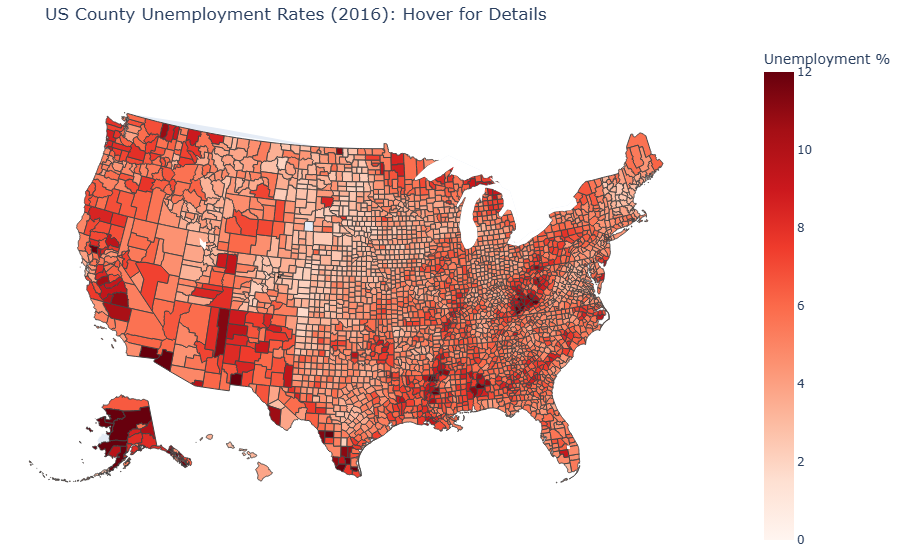

In [31]:
# Step 3: Create the choropleth map
fig = px.choropleth(
    data_frame=unemp_df,
    geojson=counties,
    locations="fips",  # column in dataframe matching GeoJSON feature id
    color="unemp",  # column to colour by
    color_continuous_scale="Reds",
    range_color=(0, 12),  # fix colour scale range
    scope="usa",
    labels={"unemp": "Unemployment Rate (%)"},
    title="US County Unemployment Rates (2016): Hover for Details",
    width=900,
    height=550,
)

fig.update_layout(
    margin=dict(l=0, r=0, t=40, b=0), coloraxis_colorbar=dict(title="Unemployment %")
)

fig.show()

# Try: hover over any county to see its unemployment rate
# Try: zoom in to a specific region

### 6.6 Animations: Visualizing Change Over Time

Plotly's `animation_frame=` argument creates an animated chart with a play button. This is one of Plotly's most impressive features and takes only one extra argument!

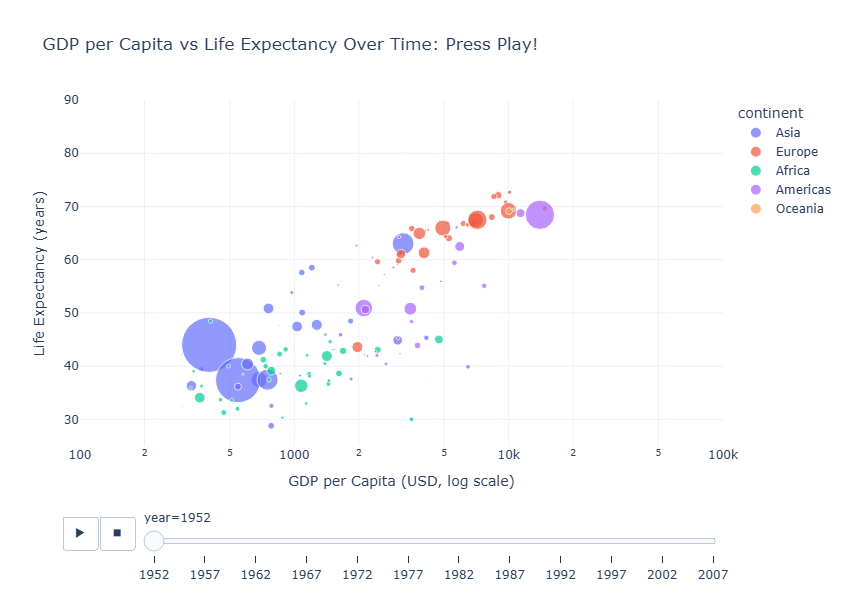

In [32]:
# --- Animated scatter: Gapminder dataset (life expectancy vs GDP over years) ---
# px includes several built-in datasets: Gapminder is a classic for animations
gapminder = px.data.gapminder()

fig = px.scatter(
    gapminder,
    x="gdpPercap",
    y="lifeExp",
    animation_frame="year",  # one frame per year
    animation_group="country",  # track each country across frames
    size="pop",  # bubble size = population
    color="continent",
    hover_name="country",
    log_x=True,  # log scale on x (GDP spans many orders of magnitude)
    size_max=60,
    range_x=[100, 100000],
    range_y=[25, 90],
    title="GDP per Capita vs Life Expectancy Over Time: Press Play!",
    labels={
        "gdpPercap": "GDP per Capita (USD, log scale)",
        "lifeExp": "Life Expectancy (years)",
    },
    template="plotly_white",
    width=850,
    height=600,
)

fig.show()

# Press the Play button to watch the world's health and wealth change from 1952 to 2007!

### 6.7 Saving Interactive Plots

Plotly charts can be saved as **standalone HTML files** that anyone can open in a browser, no Python required!

In [33]:
# --- Save a Plotly figure as an HTML file ---
# Create a simple figure to save
fig_to_save = px.scatter(
    df,
    x="body_mass_g",
    y="flipper_length_mm",
    color="species",
    title="Body Mass vs Flipper Length",
    template="plotly_white",
)

# Save as an HTML file, anyone with a browser can open this!
fig_to_save.write_html("assets/penguin_scatter_interactive.html")
print("Saved to assets/penguin_scatter_interactive.html")

# To save as a static PNG instead:
# fig_to_save.write_image('assets/penguin_scatter.png')  # requires kaleido: pip install kaleido

Saved to assets/penguin_scatter_interactive.html


---

## Checkpoint 3: Plotly

1. **Name two things you can do with a Plotly chart that you cannot do with a Matplotlib chart.**

<details>
<summary>Show answer</summary>

Plotly charts are interactive in the browser, so two examples are hovering over a point to read its exact values in a tooltip, and zooming or panning into a region (you can also click legend entries to toggle groups). Matplotlib output is static by default. Plotly can also export a chart as a standalone interactive HTML file.
</details>

2. **What is the difference between `plotly.express` (`px`) and `plotly.graph_objects` (`go`)?**
   When would you use each?

<details>
<summary>Show answer</summary>

`plotly.express` (`px`) is the high-level API: one concise call builds a full chart from a DataFrame, which covers most everyday needs. `plotly.graph_objects` (`go`) is the lower-level API where you assemble a figure trace by trace with full control. Use `px` for speed and simplicity, and drop down to `go` when you need fine control or custom widgets like a dropdown.
</details>

3. **In a `px.bar()` call, what does `barmode='stack'` do differently to `barmode='group'`?**

<details>
<summary>Show answer</summary>

With `barmode='group'` the bars for each category sit side by side, so you compare their absolute values directly. With `barmode='stack'` the bars are stacked into one bar split into parts, which is better for showing how the parts add up to a whole. Same data, different question: comparison versus composition.
</details>

4. **What is GeoJSON, and why do we need it to create a choropleth map?**

<details>
<summary>Show answer</summary>

GeoJSON is a standard text format that describes geographic shapes (the boundaries of countries, states, or counties) as coordinates. A choropleth colours each region by a value, so it needs the outline of every region to fill, and GeoJSON supplies those outlines. The data is matched to the shapes by a shared id, such as a country name or a FIPS code.
</details>

5. **In the Gapminder animation, how do you add a new variable (column) as the size of the bubbles?**

<details>
<summary>Show answer</summary>

Pass the column name to the `size=` argument, for example `size='pop'`, and Plotly scales each bubble's area to that value. You can cap the largest bubble with `size_max=` so the chart stays readable. This is independent of `animation_frame`, which controls the time steps.
</details>

> **Try it yourself**: Using the penguins dataset, create an interactive Plotly box plot (`px.box`) that shows `body_mass_g` on the y-axis, `species` on the x-axis, and is coloured by `island`. Add a title.

**My solution (Try it yourself, Plotly)**

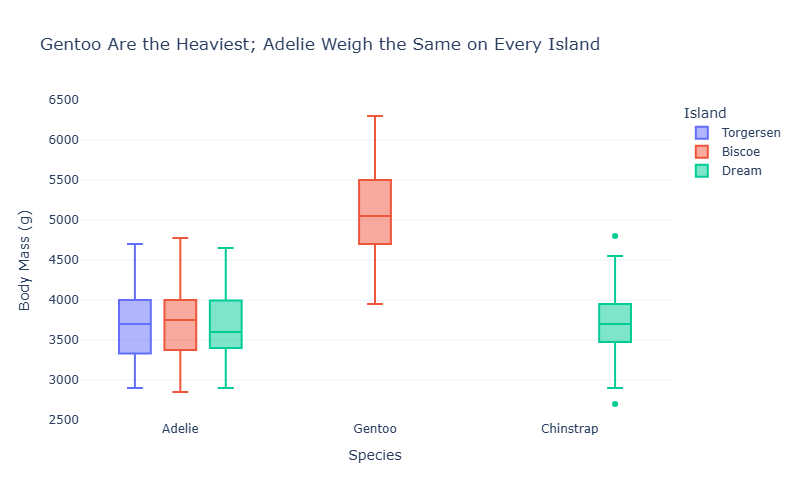

In [34]:
# --- Interactive box plot: body mass by species, coloured by island ---
fig = px.box(
    df,
    x="species",
    y="body_mass_g",
    color="island",  # one box per island inside each species
    title="Gentoo Are the Heaviest; Adelie Weigh the Same on Every Island",
    labels={"body_mass_g": "Body Mass (g)", "species": "Species", "island": "Island"},
    template="plotly_white",
    width=800,
    height=500,
)
fig.show()

# Only Adelie live on all three islands, so only Adelie gets three boxes.

---

## 7. Choosing the Right Library: Summary

Here is a practical decision guide. Ask yourself these questions:

### Question 1: Does the audience need to interact with the chart?
- **Yes** → Plotly
- **No** → Matplotlib or Seaborn

### Question 2: Do you need automatic statistical summaries?
(regression lines, confidence intervals, KDE curves, correlation matrices)
- **Yes** → Seaborn
- **No** → Either Matplotlib or Plotly depending on audience

### Question 3: Is this for EDA or for a polished final output?
- **EDA (quick exploration)** → Seaborn (beautiful defaults, minimal code)
- **Final output for publication** → Matplotlib (precise control)
- **Final output for a web report** → Plotly (interactive HTML)

### Question 4: Do you need unusual customisation?
(non-standard plot types, precise annotation placement, custom artists)
- **Yes** → Matplotlib
- **No** → Seaborn or Plotly are sufficient

### Real-World Usage

| Context | Recommended library |
|---|---|
| Quick EDA in a Jupyter notebook | Seaborn |
| Report figure for a PDF or paper | Matplotlib |
| Dashboard or stakeholder presentation | Plotly |
| Geographic / map data | Plotly |
| Animated chart | Plotly |
| Distribution comparison | Seaborn |
| Correlation matrix | Seaborn (`heatmap`) |
| Fully custom / unusual chart | Matplotlib |


In [35]:
# --- Side-by-side: The SAME scatter plot in all three libraries ---
# This is the clearest way to see the differences in syntax

print("=== MATPLOTLIB ===")
print("""
fig, ax = plt.subplots(figsize=(8, 6))
for sp in df['species'].unique():
    subset = df[df['species'] == sp]
    ax.scatter(subset['bill_length_mm'], subset['bill_depth_mm'], label=sp, alpha=0.7)
ax.set_xlabel('Bill Length (mm)')
ax.set_ylabel('Bill Depth (mm)')
ax.legend()
plt.show()
# Lines of code: ~7
""")

print("=== SEABORN ===")
print("""
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', hue='species')
# Lines of code: 1
""")

print("=== PLOTLY ===")
print("""
fig = px.scatter(df, x='bill_length_mm', y='bill_depth_mm', color='species')
fig.show()
# Lines of code: 2: AND you get interactivity for free!
""")

=== MATPLOTLIB ===

fig, ax = plt.subplots(figsize=(8, 6))
for sp in df['species'].unique():
    subset = df[df['species'] == sp]
    ax.scatter(subset['bill_length_mm'], subset['bill_depth_mm'], label=sp, alpha=0.7)
ax.set_xlabel('Bill Length (mm)')
ax.set_ylabel('Bill Depth (mm)')
ax.legend()
plt.show()
# Lines of code: ~7

=== SEABORN ===

sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', hue='species')
# Lines of code: 1

=== PLOTLY ===

fig = px.scatter(df, x='bill_length_mm', y='bill_depth_mm', color='species')
fig.show()
# Lines of code: 2: AND you get interactivity for free!



---

## 8. Key Takeaways

### What you have learned

**Matplotlib**
- The foundation, everything else is built on it
- `fig, ax = plt.subplots()` is the recommended entry point
- Most verbose but offers unlimited control
- Best for final publication-quality static figures

**Seaborn**
- Built on Matplotlib, but far more concise for statistical plots
- Use `hue=`, `col=`, `row=` to split by categorical variables automatically
- `pairplot` and `heatmap` are essential EDA tools
- Two API levels: axes-level functions and figure-level functions

**Plotly**
- Interactive by default, hover, zoom, pan, export
- Use `plotly.express` (`px`) for the vast majority of charts
- Outstanding for maps, animations, and dashboards
- Charts can be shared as standalone HTML files

### The Golden Rule

> Pick the **simplest** library that meets your needs. Reach for Plotly only when interactivity matters, Seaborn when statistics matter, and Matplotlib when control matters.

### Next Steps

You are now ready to apply these skills to a real dataset!

Head to **[3_Fetching_the_data](3_Fetching_the_data.ipynb)** to start practising. 